# 04 - Imbalance experiments (WP-B1)

Question: do imbalance methods help on this data? Ten methods (E0-E9) are compared with the **same model** (LightGBM), the **same feature set** (`F_TIMING`) and the **same session-grouped CV** (`src/cv.py`). Every result is written by `run_cv()` to `reports/results_imbalance.csv`.

Columns to watch most: `macro_f1_broken`, Bot/DDoS/Prob recall and `bot_ddos_confusion`.

## 1. Setup
Imports and named constants. Column lists come only from `src/config.py` (CLAUDE.md rule 7).

In [1]:
import itertools
import os
import time
import sys
sys.path.append('..')

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.config import DATA_PATH, F_TIMING
from src.preprocessing import clean
from imblearn.combine import SMOTETomek
from imblearn.ensemble import BalancedRandomForestClassifier
from imblearn.over_sampling import BorderlineSMOTE, RandomOverSampler, SMOTE
from imblearn.pipeline import Pipeline
from imblearn.under_sampling import EditedNearestNeighbours, RandomUnderSampler
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from lightgbm import LGBMClassifier

from src.cv import (CLASSES, append_row, compute_metrics, drop_conflicts, get_folds, get_random_folds,
                    make_confusion, print_fold_table, run_cv, subset_macro_f1)

# Plan section 8: sampler targets
TARGET_MINORITY = 30_000   # Bot, Prob (E3-E6)
TARGET_MAJORITY = 50_000   # Benign, Dos (E2)
MINORITY_CLASSES = ['Bot', 'Prob']
MAJORITY_CLASSES = ['Benign', 'Dos']
RANDOM_STATE = 42
BRF_TREES = 200            # E8, plan section 8
WEIGHT_GRID = [0.5, 1.0, 1.5, 2.0, 2.5, 3.0]   # E9, plan section 8: 0.5-3.0
TUNED_CLASSES = ['Bot', 'DDoS', 'Prob']       # E9: only these get a weight

OUT_CSV = '../reports/results_imbalance.csv'
FEATURE_SET = 'F_TIMING'

# Grafik renkleri (kategorik, sabit sıra; renk körlüğü kontrolünden geçti)
COLOR_ALL = '#257de0'      # blue
COLOR_BROKEN = '#f47230'   # orange
COLOR_THIRD = '#00b894'    # aqua
GRID_COLOR = '#e0e0e0'
GROUPED_ORDER = ['E0', 'E1', 'E2', 'E3', 'E4', 'E5', 'E6', 'E7', 'E8', 'E9']

## 2. Load and clean the data
Same `clean()` as every other package (WP-0A).

In [2]:
raw = pd.read_csv(DATA_PATH)
df = clean(raw)
print(df.shape)
print(df['Label'].value_counts())

clean: dropped 70 rows with inf/NaN
clean: clipped negative values to 0 in 427 rows


clean: removed 29930 duplicate rows (features + label)


clean: final shape (427044, 63)
(427044, 63)
Label
Benign    233747
Dos       126506
DDoS       50269
Bot         8957
Prob        7565
Name: count, dtype: int64


## 3. Folds and class counts in each training fold
The sampler targets must fit every training fold: 30,000 must be **larger** than the Bot/Prob count (oversampling), and 50,000 must be **smaller** than the Benign/Dos count (undersampling). Otherwise imbalanced-learn raises an error.

In [3]:
folds = get_folds(df)
print_fold_table(df, folds)

train_counts = {}
for fold_no, (train_idx, test_idx) in enumerate(folds):
    train_counts['fold_' + str(fold_no)] = df['Label'].iloc[train_idx].value_counts()
train_counts = pd.DataFrame(train_counts)
print('Training-fold class counts:')
print(train_counts)

for name in MINORITY_CLASSES:
    ok = (train_counts.loc[name] < TARGET_MINORITY).all()
    print(f'{name}: every training fold < {TARGET_MINORITY:,} ->', ok)
for name in MAJORITY_CLASSES:
    ok = (train_counts.loc[name] > TARGET_MAJORITY).all()
    print(f'{name}: every training fold > {TARGET_MAJORITY:,} ->', ok)

Test kısmındaki satır sayıları (sınıf × kat):
        fold_0  fold_1  fold_2
Label                         
Benign   76910   79965   76872
Bot       1757    2585    4615
DDoS     23953   10599   15717
Dos      16482   16711   93313
Prob      2803    2316    2446
Test kısmındaki oturum sayıları (sınıf × kat):
        fold_0  fold_1  fold_2
Label                         
Benign       9       3      11
Bot          1       1       1
DDoS         1       1       2
Dos         19       3       1
Prob         1       1       4
Training-fold class counts:
        fold_0  fold_1  fold_2
Label                         
Benign  156837  153782  156875
Bot       7200    6372    4342
DDoS     26316   39670   34552
Dos     110024  109795   33193
Prob      4762    5249    5119
Bot: every training fold < 30,000 -> True
Prob: every training fold < 30,000 -> True
Benign: every training fold > 50,000 -> True
Dos: every training fold > 50,000 -> False


## 4. Negative values in `F_TIMING`
E4-E7 put `log1p` in front of the model; `log1p` is undefined below -1, so there must be no negative values.

In [4]:
n_negative = (df[F_TIMING] < 0).sum().sum()
print('Negative values in F_TIMING:', n_negative)
assert n_negative == 0

Negative values in F_TIMING: 0


## 5. Start a fresh results file
`run_cv` appends rows. The old file is removed so that Restart + Run All gives exactly one row per experiment.

In [5]:
if os.path.exists(OUT_CSV):
    os.remove(OUT_CSV)
    print('Removed old', OUT_CSV)
else:
    print('No old file')

Removed old ../reports/results_imbalance.csv


## 6. E0 - Baseline and E1 - Class weight
E0 does nothing about imbalance; it is the reference point. E1 keeps every row but makes a mistake on a small class cost more (`class_weight="balanced"`: weight = n_rows / (n_classes x n_rows_of_class)).
`make_model()` gives the fixed experiment model (CLAUDE.md rule 5); only E1 changes `class_weight`.

In [6]:
def make_model(class_weight=None):
    """Sabit deney modeli (Kural 5): LightGBM, varsayılan parametreler."""
    return LGBMClassifier(random_state=RANDOM_STATE, verbose=-1, class_weight=class_weight)


results = {}   # deney kodu -> (row, confusion matrix, OOF tahminleri)

pipe_e0 = Pipeline([('model', make_model())])
results['E0'] = run_cv(pipe_e0, df, F_TIMING, OUT_CSV, experiment='E0',
                       sampler='none', feature_set=FEATURE_SET, folds=folds)

Kat 0


  eğitim: 301069 satır (çelişki atılan: 4070 ) | test: 121905 | fit: 2.2 sn
Kat 1


  eğitim: 309862 satır (çelişki atılan: 5006 ) | test: 112176 | fit: 2.2 sn
Kat 2


  eğitim: 230078 satır (çelişki atılan: 4003 ) | test: 192963 | fit: 1.9 sn


Kat F1'leri: [0.4262 0.5334 0.2952] → 0.4183 ± 0.1193
CSV'ye eklendi: ../reports/results_imbalance.csv


In [7]:
pipe_e1 = Pipeline([('model', make_model(class_weight='balanced'))])
results['E1'] = run_cv(pipe_e1, df, F_TIMING, OUT_CSV, experiment='E1',
                       sampler='class_weight', feature_set=FEATURE_SET, folds=folds,
                       note='class_weight=balanced')

Kat 0


  eğitim: 301069 satır (çelişki atılan: 4070 ) | test: 121905 | fit: 2.2 sn
Kat 1


  eğitim: 309862 satır (çelişki atılan: 5006 ) | test: 112176 | fit: 2.3 sn
Kat 2


  eğitim: 230078 satır (çelişki atılan: 4003 ) | test: 192963 | fit: 1.9 sn


Kat F1'leri: [0.3776 0.5089 0.3059] → 0.3975 ± 0.1029
CSV'ye eklendi: ../reports/results_imbalance.csv


Short comparison of E0 and E1 (the main columns of the plan).

In [8]:
SHOW_COLS = ['experiment', 'macro_f1_mean', 'macro_f1_std', 'macro_f1_clean', 'macro_f1_broken',
             'recall_Bot', 'recall_DDoS', 'recall_Prob', 'bot_ddos_confusion', 'fit_time_s']
print(pd.read_csv(OUT_CSV)[SHOW_COLS].round(3).to_string(index=False))

experiment  macro_f1_mean  macro_f1_std  macro_f1_clean  macro_f1_broken  recall_Bot  recall_DDoS  recall_Prob  bot_ddos_confusion  fit_time_s
        E0          0.418         0.119           0.512            0.324       0.031        0.713        0.275               0.140       2.070
        E1          0.397         0.103           0.502            0.277       0.667        0.413        0.534               0.377       2.122


## 7. E2 - RandomUnderSampler and E3 - RandomOverSampler
E2 throws away rows of the big classes (Benign, Dos -> 50,000). E3 copies rows of the small classes (Bot, Prob -> 30,000). Both run inside the pipeline, so they only touch the training fold (CLAUDE.md rule 4).

Section 3 showed that fold 2's training part has only 33,193 Dos rows, so "Dos -> 50,000" is impossible there. Decision (log WP-B1, step 1): the target for each big class is **min(50,000, rows available)**, computed inside each training fold.

In [9]:
def majority_targets(y):
    """E2 hedefi: Benign ve Dos için min(TARGET_MAJORITY, eğitim katındaki sayı).

    imblearn bu fonksiyonu her eğitim katında y ile çağırır; {sınıf: hedef} döndürür.
    """
    counts = pd.Series(y).value_counts()
    targets = {}
    for name in MAJORITY_CLASSES:
        # Kat 2'de Dos 33.193 < 50.000; undersampler sayıyı artıramaz (Adım 1 kararı).
        targets[name] = min(TARGET_MAJORITY, counts[name])
    return targets


minority_targets = {}
for name in MINORITY_CLASSES:
    minority_targets[name] = TARGET_MINORITY
print('E3 targets:', minority_targets)

E3 targets: {'Bot': 30000, 'Prob': 30000}


Check: class counts of each training fold after the sampler (conflict removal in `run_cv` happens before the sampler, so real numbers are a little lower).

In [10]:
under = RandomUnderSampler(sampling_strategy=majority_targets, random_state=RANDOM_STATE)
over = RandomOverSampler(sampling_strategy=minority_targets, random_state=RANDOM_STATE)

after = {}
for fold_no, (train_idx, test_idx) in enumerate(folds):
    train = df.iloc[train_idx]
    X_u, y_u = under.fit_resample(train[F_TIMING], train['Label'])
    X_o, y_o = over.fit_resample(train[F_TIMING], train['Label'])
    after['E2_fold_' + str(fold_no)] = pd.Series(y_u).value_counts()
    after['E3_fold_' + str(fold_no)] = pd.Series(y_o).value_counts()
print(pd.DataFrame(after))

        E2_fold_0  E3_fold_0  E2_fold_1  E3_fold_1  E2_fold_2  E3_fold_2
Label                                                                   
Benign      50000     156837      50000     153782      50000     156875
Bot          7200      30000       6372      30000       4342      30000
DDoS        26316      26316      39670      39670      34552      34552
Dos         50000     110024      50000     109795      33193      33193
Prob         4762      30000       5249      30000       5119      30000


In [11]:
pipe_e2 = Pipeline([('sampler', RandomUnderSampler(sampling_strategy=majority_targets,
                                                   random_state=RANDOM_STATE)),
                    ('model', make_model())])
results['E2'] = run_cv(pipe_e2, df, F_TIMING, OUT_CSV, experiment='E2',
                       sampler='RandomUnderSampler', feature_set=FEATURE_SET, folds=folds,
                       note='Benign, Dos -> min(50k, available); fold 2 Dos stays 33k')

Kat 0


  eğitim: 301069 satır (çelişki atılan: 4070 ) | test: 121905 | fit: 1.9 sn
Kat 1


  eğitim: 309862 satır (çelişki atılan: 5006 ) | test: 112176 | fit: 2.1 sn
Kat 2


  eğitim: 230078 satır (çelişki atılan: 4003 ) | test: 192963 | fit: 1.9 sn


Kat F1'leri: [0.435  0.5418 0.3054] → 0.4274 ± 0.1184
CSV'ye eklendi: ../reports/results_imbalance.csv


In [12]:
pipe_e3 = Pipeline([('sampler', RandomOverSampler(sampling_strategy=minority_targets,
                                                  random_state=RANDOM_STATE)),
                    ('model', make_model())])
results['E3'] = run_cv(pipe_e3, df, F_TIMING, OUT_CSV, experiment='E3',
                       sampler='RandomOverSampler', feature_set=FEATURE_SET, folds=folds,
                       note='Bot, Prob -> 30k')

Kat 0


  eğitim: 301069 satır (çelişki atılan: 4070 ) | test: 121905 | fit: 2.8 sn
Kat 1


  eğitim: 309862 satır (çelişki atılan: 5006 ) | test: 112176 | fit: 2.8 sn
Kat 2


  eğitim: 230078 satır (çelişki atılan: 4003 ) | test: 192963 | fit: 2.5 sn


Kat F1'leri: [0.3836 0.5642 0.3273] → 0.425 ± 0.1238
CSV'ye eklendi: ../reports/results_imbalance.csv


In [13]:
print(pd.read_csv(OUT_CSV)[SHOW_COLS].round(3).to_string(index=False))

experiment  macro_f1_mean  macro_f1_std  macro_f1_clean  macro_f1_broken  recall_Bot  recall_DDoS  recall_Prob  bot_ddos_confusion  fit_time_s
        E0          0.418         0.119           0.512            0.324       0.031        0.713        0.275               0.140       2.070
        E1          0.397         0.103           0.502            0.277       0.667        0.413        0.534               0.377       2.122
        E2          0.427         0.118           0.527            0.326       0.030        0.824        0.344               0.148       1.980
        E3          0.425         0.124           0.524            0.322       0.542        0.365        0.459               0.340       2.695


## 8. E4-E7 - Distance-based samplers
SMOTE (E4) makes new rows between a small-class row and its neighbours; BorderlineSMOTE (E5) does this only near the class border; SMOTETomek (E6) runs SMOTE and then deletes mixed pairs at the border; EditedNearestNeighbours (E7) deletes rows whose neighbours have a different class (default settings).

All four use distances, so the pipeline first applies `log1p` (timing values span many orders of magnitude) and `StandardScaler`. Both are fitted on the training fold only (CLAUDE.md rule 4). Measured time on the largest training fold: SMOTE 0.6 s, BorderlineSMOTE 2.9 s, ENN 41 s, SMOTETomek 44 s.

In [14]:
def distance_pipeline(sampler):
    """E4-E7 pipeline'ı: log1p -> StandardScaler -> sampler -> sabit model."""
    return Pipeline([('log', FunctionTransformer(np.log1p)),
                     ('scale', StandardScaler()),
                     ('sampler', sampler),
                     ('model', make_model())])


distance_experiments = [
    ('E4', 'SMOTE', SMOTE(sampling_strategy=minority_targets, random_state=RANDOM_STATE),
     'log1p + scaler; Bot, Prob -> 30k'),
    ('E5', 'BorderlineSMOTE', BorderlineSMOTE(sampling_strategy=minority_targets, random_state=RANDOM_STATE),
     'log1p + scaler; Bot, Prob -> 30k'),
    ('E6', 'SMOTETomek', SMOTETomek(smote=SMOTE(sampling_strategy=minority_targets, random_state=RANDOM_STATE),
                                    random_state=RANDOM_STATE),
     'log1p + scaler; Bot, Prob -> 30k, then Tomek links'),
    ('E7', 'EditedNearestNeighbours', EditedNearestNeighbours(),
     'log1p + scaler; ENN default'),
]

for code_name, sampler_name, sampler, note in distance_experiments:
    print('=====', code_name, sampler_name)
    results[code_name] = run_cv(distance_pipeline(sampler), df, F_TIMING, OUT_CSV,
                                experiment=code_name, sampler=sampler_name,
                                feature_set=FEATURE_SET, folds=folds, note=note)

===== E4 SMOTE
Kat 0


  eğitim: 301069 satır (çelişki atılan: 4070 ) | test: 121905 | fit: 3.2 sn
Kat 1


  eğitim: 309862 satır (çelişki atılan: 5006 ) | test: 112176 | fit: 3.0 sn
Kat 2


  eğitim: 230078 satır (çelişki atılan: 4003 ) | test: 192963 | fit: 2.7 sn


Kat F1'leri: [0.3737 0.5538 0.3289] → 0.4188 ± 0.1191
CSV'ye eklendi: ../reports/results_imbalance.csv


===== E5 BorderlineSMOTE
Kat 0


... (10 outputs left out)

  eğitim: 301069 satır (çelişki atılan: 4070 ) | test: 121905 | fit: 41.2 sn
Kat 1


  eğitim: 309862 satır (çelişki atılan: 5006 ) | test: 112176 | fit: 18.0 sn
Kat 2


  eğitim: 230078 satır (çelişki atılan: 4003 ) | test: 192963 | fit: 15.4 sn


Kat F1'leri: [0.3425 0.4743 0.3326] → 0.3832 ± 0.0791
CSV'ye eklendi: ../reports/results_imbalance.csv


How many rows does ENN keep? On fold 0 it removed most Bot and DDoS rows, because in the broken subset these two classes sit on top of each other.

In [15]:
enn_counts = {}
for fold_no, (train_idx, test_idx) in enumerate(folds):
    train = df.iloc[train_idx]
    X_scaled = StandardScaler().fit_transform(np.log1p(train[F_TIMING]))
    X_enn, y_enn = EditedNearestNeighbours().fit_resample(X_scaled, train['Label'])
    enn_counts['before_fold_' + str(fold_no)] = train['Label'].value_counts()
    enn_counts['after_fold_' + str(fold_no)] = pd.Series(y_enn).value_counts()
print(pd.DataFrame(enn_counts))

        before_fold_0  after_fold_0  before_fold_1  after_fold_1  \
Label                                                              
Benign         156837        136009         153782        127003   
Bot              7200           782           6372           500   
DDoS            26316          5994          39670          9579   
Dos            110024         96994         109795         94876   
Prob             4762          4762           5249          5249   

        before_fold_2  after_fold_2  
Label                                
Benign         156875        131139  
Bot              4342          4342  
DDoS            34552          9075  
Dos             33193         26902  
Prob             5119          1950  


In [16]:
print(pd.read_csv(OUT_CSV)[SHOW_COLS].round(3).to_string(index=False))

experiment  macro_f1_mean  macro_f1_std  macro_f1_clean  macro_f1_broken  recall_Bot  recall_DDoS  recall_Prob  bot_ddos_confusion  fit_time_s
        E0          0.418         0.119           0.512            0.324       0.031        0.713        0.275               0.140       2.070
        E1          0.397         0.103           0.502            0.277       0.667        0.413        0.534               0.377       2.122
        E2          0.427         0.118           0.527            0.326       0.030        0.824        0.344               0.148       1.980
        E3          0.425         0.124           0.524            0.322       0.542        0.365        0.459               0.340       2.695
        E4          0.419         0.119           0.526            0.316       0.575        0.353        0.434               0.340       2.953
        E5          0.407         0.115           0.511            0.305       0.517        0.362        0.461               0.342       4.769

**Note on E7.** ENN's default `sampling_strategy="auto"` cleans every class except the smallest one, and the smallest class is not the same in every fold: in folds 0 and 1 it is Prob, so Bot is cleaned (7,200 -> 782 rows in fold 0); in fold 2 it is Bot, so Bot is kept and Prob is cleaned (5,119 -> 1,950). So E7 does a different thing in each fold. We kept the plan's default and did not try other settings: choosing a setting after seeing these results, on the same folds, would be a hyperparameter search (CLAUDE.md rule 1) and would give an optimistic score.

**Reproducibility.** E7 changes a little between runs (macro F1 0.380 vs 0.388 in two Restart + Run All). ENN keeps exactly the same rows each time, but LightGBM's multi-threaded histogram building gives slightly different trees on ENN's output (about 12,000 different test predictions in fold 0; zero with `deterministic=True, force_row_wise=True`). The other experiments repeat exactly. We kept the fixed default model (CLAUDE.md rule 5); the change is far below the fold-to-fold std (~0.08) and does not change the ranking.

## 9. E8 - BalancedRandomForest
A different model: a random forest in which every tree is trained on a balanced bootstrap sample (each class is undersampled to the size of the smallest class). This is the only experiment that does not use LightGBM, so the `note` column says "model RF".

In [17]:
brf = BalancedRandomForestClassifier(n_estimators=BRF_TREES, n_jobs=-1, random_state=RANDOM_STATE)
pipe_e8 = Pipeline([('model', brf)])
results['E8'] = run_cv(pipe_e8, df, F_TIMING, OUT_CSV, experiment='E8',
                       sampler='BalancedRandomForest', feature_set=FEATURE_SET, folds=folds,
                       note='model RF (n_estimators=200)')

Kat 0


  eğitim: 301069 satır (çelişki atılan: 4070 ) | test: 121905 | fit: 3.7 sn
Kat 1


  eğitim: 309862 satır (çelişki atılan: 5006 ) | test: 112176 | fit: 3.8 sn
Kat 2


  eğitim: 230078 satır (çelişki atılan: 4003 ) | test: 192963 | fit: 2.9 sn


Kat F1'leri: [0.3794 0.5382 0.4396] → 0.4524 ± 0.0802
CSV'ye eklendi: ../reports/results_imbalance.csv


In [18]:
print(pd.read_csv(OUT_CSV)[SHOW_COLS].round(3).to_string(index=False))

experiment  macro_f1_mean  macro_f1_std  macro_f1_clean  macro_f1_broken  recall_Bot  recall_DDoS  recall_Prob  bot_ddos_confusion  fit_time_s
        E0          0.418         0.119           0.512            0.324       0.031        0.713        0.275               0.140       2.070
        E1          0.397         0.103           0.502            0.277       0.667        0.413        0.534               0.377       2.122
        E2          0.427         0.118           0.527            0.326       0.030        0.824        0.344               0.148       1.980
        E3          0.425         0.124           0.524            0.322       0.542        0.365        0.459               0.340       2.695
        E4          0.419         0.119           0.526            0.316       0.575        0.353        0.434               0.340       2.953
        E5          0.407         0.115           0.511            0.305       0.517        0.362        0.461               0.342       4.769

## 10. E9 - Threshold tuning
The model stays E0. After `predict_proba`, the probabilities of Bot, DDoS and Prob are multiplied by weights (0.5-3.0) and the class with the highest adjusted value wins. This moves the decision border without changing the model.

The weights must **not** be chosen on the test fold, otherwise the score is optimistic (plan section 8). So, inside each outer training fold:
1. The training fold is split again with `get_folds()` (same session-grouped rule). The inner validation part is the **first inner fold that contains all five classes**. Why: an outer training fold has only 2 Bot sessions, so one of the 3 inner folds has no Bot. A first version always used inner fold 0, which had no Bot in any outer fold; Bot's weight was then always the lowest (0.5) and Bot recall fell to 0.003 (log WP-B1, step 6).
2. E0 is fitted on the inner training part and predicts probabilities on the inner validation part.
3. All 6 x 6 x 6 = 216 weight combinations are tried; the one with the best **broken-subset macro F1** on the inner validation part is kept.
4. E0 is fitted again on the whole outer training fold; the chosen weights are applied to its probabilities on the outer test fold.

This does not fit into `run_cv()`, so the loop is written here; the folds come from `get_folds()` and every metric comes from the `src/cv.py` helpers (`compute_metrics`, `subset_macro_f1`, `make_confusion`, `append_row`).

In [19]:
def apply_weights(proba, classes, weights):
    """Olasılıkları sınıf katsayılarıyla çarpar, en yüksek değerli sınıfı döndürür.

    weights: {sınıf: katsayı}; sözlükte olmayan sınıfların katsayısı 1.
    """
    adjusted = proba.copy()
    for col, class_name in enumerate(classes):
        adjusted[:, col] = adjusted[:, col] * weights.get(class_name, 1.0)
    return np.asarray(classes)[np.argmax(adjusted, axis=1)]


def choose_weights(proba, classes, y_val, broken_val):
    """İç validation'da 216 katsayı kombinasyonunu dener; bozuk F1'i en iyi olanı döndürür.

    Dönüş: (en iyi {sınıf: katsayı} sözlüğü, o kombinasyonun bozuk macro F1'i).
    """
    best_weights = {}
    best_score = -1.0
    for combo in itertools.product(WEIGHT_GRID, repeat=len(TUNED_CLASSES)):
        weights = dict(zip(TUNED_CLASSES, combo))
        pred = apply_weights(proba, classes, weights)
        score = subset_macro_f1(y_val[broken_val], pred[broken_val], CLASSES)
        # Eşitlikte ilk bulunan kalır (grid sırası), böylece sonuç tekrarlanabilir.
        if score > best_score:
            best_score = score
            best_weights = weights
    return best_weights, best_score

In [20]:
def pick_inner_validation(train, inner_folds):
    """İç katlardan, testinde 5 sınıfın hepsi olan ilkini seçer; (iç eğitim, iç validation) döndürür.

    Dış eğitim katında Bot'un 2 oturumu var; 3 iç kattan biri Bot'suz kalır (Adım 6).
    """
    for inner_train_idx, inner_val_idx in inner_folds:
        val_classes = set(train['Label'].iloc[inner_val_idx])
        train_classes = set(train['Label'].iloc[inner_train_idx])
        if val_classes == set(CLASSES) and train_classes == set(CLASSES):
            return train.iloc[inner_train_idx], train.iloc[inner_val_idx]
    raise ValueError('No inner fold contains all five classes')


def run_e9_fold(train):
    """Tek dış kat için E9: iç bölmede katsayı seç, tüm eğitim katında yeniden fit et.

    train: çelişkileri atılmış dış eğitim katı. Dönüş: (fit edilmiş model, seçilen katsayılar).
    """
    train = train.reset_index(drop=True)
    inner_train, inner_val = pick_inner_validation(train, get_folds(train))
    print('  inner train:', len(inner_train), '| inner validation:', len(inner_val),
          '| validation classes:', dict(inner_val['Label'].value_counts()))

    inner_model = make_model().fit(inner_train[F_TIMING], inner_train['Label'])
    proba_val = inner_model.predict_proba(inner_val[F_TIMING])
    weights, val_score = choose_weights(proba_val, inner_model.classes_,
                                        inner_val['Label'].to_numpy(), inner_val['broken'].to_numpy())
    print('  chosen weights:', weights, '| inner broken F1:', round(val_score, 4))

    model = make_model().fit(train[F_TIMING], train['Label'])
    return model, weights

Outer loop: `run_e9()` works on any list of folds, so the same code is used for the grouped folds here and for the random folds in section 11. The result row has the same columns as `run_cv()` writes.

In [21]:
def run_e9(fold_list):
    """E9'u verilen katlarda çalıştırır. (kat F1'leri, OOF tahminleri, süreler, katsayılar) döndürür."""
    y_true = df['Label'].to_numpy()
    oof = np.empty(len(df), dtype=object)
    fold_f1s = []
    fit_times = []
    predict_seconds = 0.0
    chosen = []

    for fold_no, (train_idx, test_idx) in enumerate(fold_list):
        print('Fold', fold_no)
        train = drop_conflicts(df.iloc[train_idx], F_TIMING)   # Kural 4: sadece eğitim katında
        test = df.iloc[test_idx]

        start = time.perf_counter()
        model, weights = run_e9_fold(train)
        fit_times.append(time.perf_counter() - start)

        start = time.perf_counter()
        pred = apply_weights(model.predict_proba(test[F_TIMING]), model.classes_, weights)
        predict_seconds += time.perf_counter() - start

        oof[test_idx] = pred
        fold_f1s.append(subset_macro_f1(y_true[test_idx], pred, CLASSES))
        chosen.append(weights)
        print('  outer test macro F1:', round(fold_f1s[-1], 4))
    return fold_f1s, oof, fit_times, predict_seconds, chosen

In [22]:
def save_e9_row(fold_f1s, oof, fit_times, predict_seconds, chosen, cv_name):
    """E9 sonucunu run_cv ile aynı sütunlarla CSV'ye ekler; (row, cm, OOF) döndürür."""
    y_true = df['Label'].to_numpy()
    metrics = compute_metrics(y_true, oof, df['broken'])
    row = {'experiment': 'E9', 'model': 'LGBMClassifier', 'sampler': 'threshold_tuning',
           'feature_set': FEATURE_SET, 'cv': cv_name,
           'macro_f1_mean': np.mean(fold_f1s), 'macro_f1_std': np.std(fold_f1s, ddof=1),
           'macro_f1_clean': metrics['macro_f1_clean'], 'macro_f1_broken': metrics['macro_f1_broken']}
    for class_name in CLASSES:
        row['recall_' + class_name] = metrics['recall_' + class_name]
    row['bot_ddos_confusion'] = metrics['bot_ddos_confusion']
    row['fit_time_s'] = np.mean(fit_times)
    row['pred_ms_per_flow'] = predict_seconds / len(df) * 1000
    weights_text = ' | '.join(str(w) for w in chosen)
    row['note'] = 'weights chosen on inner validation (broken F1): ' + weights_text

    print('Fold F1s:', np.round(fold_f1s, 4), '->', round(row['macro_f1_mean'], 4), '+-', round(row['macro_f1_std'], 4))
    append_row(row, OUT_CSV)
    return row, make_confusion(y_true, oof), pd.Series(oof, index=df.index)

In [23]:
e9_output = run_e9(folds)
results['E9'] = save_e9_row(*e9_output, cv_name='grouped')
print(pd.read_csv(OUT_CSV)[SHOW_COLS].round(3).to_string(index=False))

Fold 0


  inner train: 224931 | inner validation: 76138 | validation classes: {'Benign': np.int64(48375), 'Dos': np.int64(14125), 'DDoS': np.int64(9839), 'Bot': np.int64(2482), 'Prob': np.int64(1317)}


  chosen weights: {'Bot': 3.0, 'DDoS': 1.5, 'Prob': 3.0} | inner broken F1: 0.309


  outer test macro F1: 0.4012
Fold 1


  inner train: 243465 | inner validation: 66397 | validation classes: {'Benign': np.int64(46456), 'DDoS': np.int64(9855), 'Dos': np.int64(7151), 'Bot': np.int64(1617), 'Prob': np.int64(1318)}


  chosen weights: {'Bot': 3.0, 'DDoS': 1.0, 'Prob': 3.0} | inner broken F1: 0.3821


... (2 outputs left out)

  chosen weights: {'Bot': 2.0, 'DDoS': 0.5, 'Prob': 2.5} | inner broken F1: 0.3424


  outer test macro F1: 0.3225


Fold F1s: [0.4012 0.5662 0.3225] -> 0.4299 +- 0.1244
CSV'ye eklendi: ../reports/results_imbalance.csv


experiment  macro_f1_mean  macro_f1_std  macro_f1_clean  macro_f1_broken  recall_Bot  recall_DDoS  recall_Prob  bot_ddos_confusion  fit_time_s
        E0          0.418         0.119           0.512            0.324       0.031        0.713        0.275               0.140       2.070
        E1          0.397         0.103           0.502            0.277       0.667        0.413        0.534               0.377       2.122
        E2          0.427         0.118           0.527            0.326       0.030        0.824        0.344               0.148       1.980
        E3          0.425         0.124           0.524            0.322       0.542        0.365        0.459               0.340       2.695
        E4          0.419         0.119           0.526            0.316       0.575        0.353        0.434               0.340       2.953
        E5          0.407         0.115           0.511            0.305       0.517        0.362        0.461               0.342       4.769

**Note on the weight grid.** In two of the three folds the chosen Bot and Prob weights are at the top of the grid (3.0). Larger values were not tried: the grid is fixed by the plan (0.5-3.0), and changing it after seeing the outer results would be a hyperparameter search (CLAUDE.md rule 1). A very large Bot weight behaves like E1 (`class_weight="balanced"`), which lowered the broken-subset F1 (0.277), so a large gain from a wider grid is not expected; this was not measured.

## 11. Random folds: E0 and the best method
Selection rule (log WP-B1): highest `macro_f1_broken`; if the difference is below 0.01, the simpler method. On grouped folds the highest is E9 (0.340 vs E0 0.324), so E0 and E9 are run again with `get_random_folds()` on the same rows. Only the outer split changes; E9's inner validation is chosen in the same way. This checks whether a random split makes the method look better than the grouped one does.

In [24]:
random_folds = get_random_folds(df)
results['E0_random'] = run_cv(pipe_e0, df, F_TIMING, OUT_CSV, experiment='E0',
                              sampler='none', feature_set=FEATURE_SET, folds=random_folds)

Kat 0


  eğitim: 280165 satır (çelişki atılan: 4531 ) | test: 142348 | fit: 2.0 sn
Kat 1


  eğitim: 280479 satır (çelişki atılan: 4217 ) | test: 142348 | fit: 2.0 sn
Kat 2


  eğitim: 280352 satır (çelişki atılan: 4344 ) | test: 142348 | fit: 2.2 sn


Kat F1'leri: [0.6258 0.6302 0.6351] → 0.6304 ± 0.0046
CSV'ye eklendi: ../reports/results_imbalance.csv


In [25]:
e9_random_output = run_e9(random_folds)
results['E9_random'] = save_e9_row(*e9_random_output, cv_name='random')

Fold 0


  inner train: 200459 | inner validation: 79706 | validation classes: {'Benign': np.int64(50313), 'DDoS': np.int64(15874), 'Dos': np.int64(10596), 'Prob': np.int64(1850), 'Bot': np.int64(1073)}


  chosen weights: {'Bot': 2.5, 'DDoS': 2.0, 'Prob': 2.0} | inner broken F1: 0.4059


  outer test macro F1: 0.6372
Fold 1


  inner train: 200451 | inner validation: 80028 | validation classes: {'Benign': np.int64(50323), 'DDoS': np.int64(15979), 'Dos': np.int64(10811), 'Prob': np.int64(1838), 'Bot': np.int64(1077)}


  chosen weights: {'Bot': 3.0, 'DDoS': 2.0, 'Prob': 3.0} | inner broken F1: 0.3865


  outer test macro F1: 0.6422
Fold 2


  inner train: 200531 | inner validation: 79821 | validation classes: {'Benign': np.int64(50284), 'DDoS': np.int64(15983), 'Dos': np.int64(10615), 'Prob': np.int64(1842), 'Bot': np.int64(1097)}


  chosen weights: {'Bot': 3.0, 'DDoS': 2.5, 'Prob': 2.0} | inner broken F1: 0.4028


  outer test macro F1: 0.6385


Fold F1s: [0.6372 0.6422 0.6385] -> 0.6393 +- 0.0026
CSV'ye eklendi: ../reports/results_imbalance.csv


All rows of the results file (10 grouped + 2 random).

In [26]:
all_rows = pd.read_csv(OUT_CSV)
print(all_rows[['cv'] + SHOW_COLS].round(3).to_string(index=False))
print(all_rows['cv'].value_counts())
assert (all_rows['cv'] == 'grouped').sum() == 10 and (all_rows['cv'] == 'random').sum() == 2

     cv experiment  macro_f1_mean  macro_f1_std  macro_f1_clean  macro_f1_broken  recall_Bot  recall_DDoS  recall_Prob  bot_ddos_confusion  fit_time_s
grouped         E0          0.418         0.119           0.512            0.324       0.031        0.713        0.275               0.140       2.070
grouped         E1          0.397         0.103           0.502            0.277       0.667        0.413        0.534               0.377       2.122
grouped         E2          0.427         0.118           0.527            0.326       0.030        0.824        0.344               0.148       1.980
grouped         E3          0.425         0.124           0.524            0.322       0.542        0.365        0.459               0.340       2.695
grouped         E4          0.419         0.119           0.526            0.316       0.575        0.353        0.434               0.340       2.953
grouped         E5          0.407         0.115           0.511            0.305       0.517  

## 12. Plots
Plots are shown only in this notebook (no file is saved: `reports/figures/` is not part of WP-B1).

**Plot 1 - macro F1 per method, all rows and broken subset.** `run_cv` gives the all-rows score as the mean ± std over folds. For the broken subset it gives a single out-of-fold value, so the per-fold broken F1 is computed here from the same out-of-fold predictions and the same `subset_macro_f1` helper; the bar is the per-fold mean and the whisker the std.

In [27]:
def broken_f1_per_fold(oof, fold_list):
    """OOF tahminlerinden her katın test kısmındaki bozuk-satır macro F1'ini hesaplar."""
    y_true = df['Label'].to_numpy()
    broken = df['broken'].to_numpy()
    pred = np.asarray(oof)
    scores = []
    for train_idx, test_idx in fold_list:
        rows = test_idx[broken[test_idx]]
        scores.append(subset_macro_f1(y_true[rows], pred[rows], CLASSES))
    return scores


grouped_rows = all_rows[all_rows['cv'] == 'grouped'].set_index('experiment').loc[GROUPED_ORDER]
broken_mean = []
broken_std = []
for code_name in GROUPED_ORDER:
    scores = broken_f1_per_fold(results[code_name][2], folds)
    broken_mean.append(np.mean(scores))
    broken_std.append(np.std(scores, ddof=1))

plot1_table = pd.DataFrame({'all_mean': grouped_rows['macro_f1_mean'], 'all_std': grouped_rows['macro_f1_std'],
                            'broken_fold_mean': broken_mean, 'broken_fold_std': broken_std,
                            'broken_oof': grouped_rows['macro_f1_broken']}, index=GROUPED_ORDER)
print(plot1_table.round(3))

    all_mean  all_std  broken_fold_mean  broken_fold_std  broken_oof
E0     0.418    0.119             0.313            0.072       0.324
E1     0.397    0.103             0.259            0.035       0.277
E2     0.427    0.118             0.309            0.081       0.326
E3     0.425    0.124             0.313            0.032       0.322
E4     0.419    0.119             0.305            0.025       0.316
E5     0.407    0.115             0.295            0.031       0.305
E6     0.414    0.120             0.303            0.022       0.312
E7     0.383    0.079             0.291            0.020       0.310
E8     0.452    0.080             0.256            0.019       0.267
E9     0.430    0.124             0.333            0.054       0.340


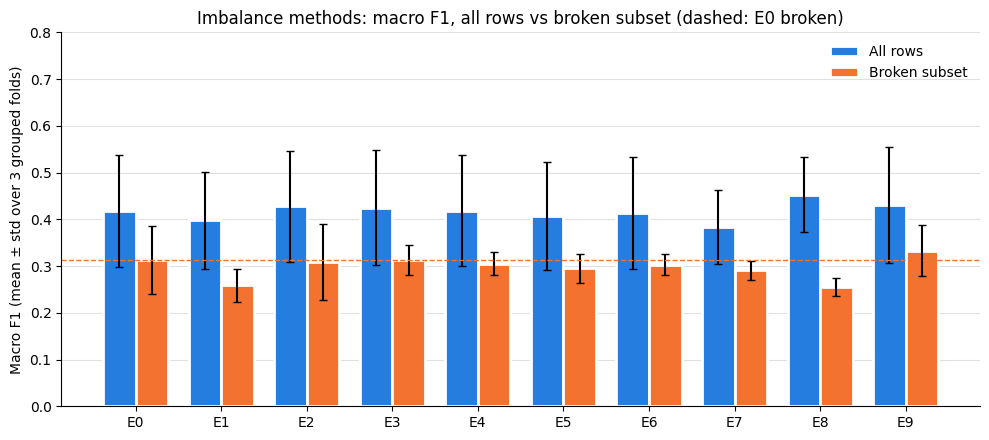

In [28]:
positions = np.arange(len(GROUPED_ORDER))
bar_width = 0.38
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(positions - bar_width / 2, plot1_table['all_mean'], bar_width, yerr=plot1_table['all_std'],
       color=COLOR_ALL, edgecolor='white', linewidth=2, capsize=3, label='All rows')
ax.bar(positions + bar_width / 2, plot1_table['broken_fold_mean'], bar_width, yerr=plot1_table['broken_fold_std'],
       color=COLOR_BROKEN, edgecolor='white', linewidth=2, capsize=3, label='Broken subset')
ax.axhline(plot1_table.loc['E0', 'broken_fold_mean'], color=COLOR_BROKEN, linewidth=1, linestyle='--')
ax.set_xticks(positions)
ax.set_xticklabels(GROUPED_ORDER)
ax.set_ylabel('Macro F1 (mean ± std over 3 grouped folds)')
ax.set_title('Imbalance methods: macro F1, all rows vs broken subset (dashed: E0 broken)')
ax.set_ylim(0, 0.8)
ax.grid(axis='y', color=GRID_COLOR)
ax.set_axisbelow(True)
ax.spines[['top', 'right']].set_visible(False)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

**Plot 2 - recall of the three small attack classes** (out-of-fold, grouped CV). Methods that raise Bot recall usually lower DDoS recall.

            recall_Bot  recall_DDoS  recall_Prob
experiment                                      
E0               0.031        0.713        0.275
E1               0.667        0.413        0.534
E2               0.030        0.824        0.344
E3               0.542        0.365        0.459
E4               0.575        0.353        0.434
E5               0.517        0.362        0.461
E6               0.591        0.328        0.451
E7               0.207        0.537        0.361
E8               0.398        0.534        0.525
E9               0.289        0.514        0.377


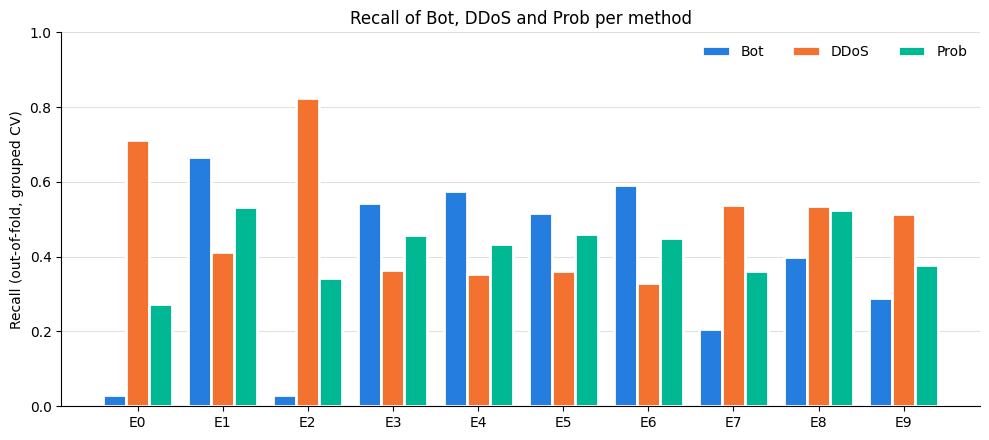

In [29]:
recall_table = grouped_rows[['recall_Bot', 'recall_DDoS', 'recall_Prob']]
print(recall_table.round(3))

bar_width = 0.27
fig, ax = plt.subplots(figsize=(10, 4.5))
series = [('recall_Bot', 'Bot', COLOR_ALL), ('recall_DDoS', 'DDoS', COLOR_BROKEN), ('recall_Prob', 'Prob', COLOR_THIRD)]
for offset, (column, label, color) in zip([-bar_width, 0, bar_width], series):
    ax.bar(positions + offset, recall_table[column], bar_width, color=color,
           edgecolor='white', linewidth=2, label=label)
ax.set_xticks(positions)
ax.set_xticklabels(GROUPED_ORDER)
ax.set_ylabel('Recall (out-of-fold, grouped CV)')
ax.set_title('Recall of Bot, DDoS and Prob per method')
ax.set_ylim(0, 1)
ax.grid(axis='y', color=GRID_COLOR)
ax.set_axisbelow(True)
ax.spines[['top', 'right']].set_visible(False)
ax.legend(frameon=False, ncol=3)
plt.tight_layout()
plt.show()

**Plot 3 - confusion matrices on the broken subset** for E0 and the best method (E9), grouped CV. Rows are the true class and sum to 1 (row-normalised), so each diagonal cell is that class's recall on broken rows.

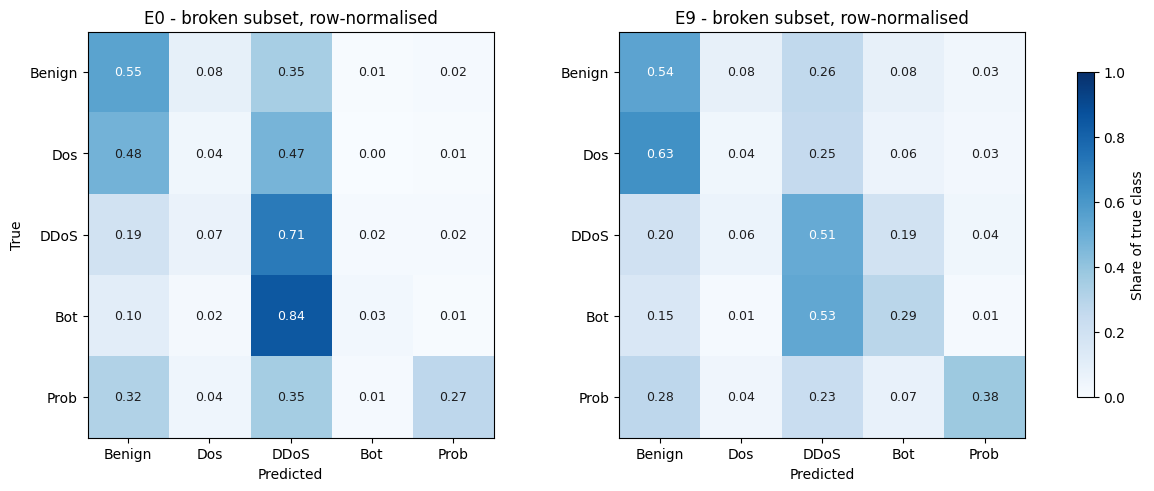

Broken rows per class: {'DDoS': np.int64(50269), 'Benign': np.int64(41937), 'Dos': np.int64(15693), 'Bot': np.int64(8957), 'Prob': np.int64(7565)}


In [30]:
def broken_confusion(oof):
    """Bozuk satırlarda satır-normalize confusion matrix (satır = gerçek sınıf)."""
    broken = df['broken'].to_numpy()
    cm = make_confusion(df['Label'].to_numpy()[broken], np.asarray(oof)[broken])
    return cm.div(cm.sum(axis=1), axis=0)


fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), constrained_layout=True)
for ax, code_name in zip(axes, ['E0', 'E9']):
    cm = broken_confusion(results[code_name][2])
    image = ax.imshow(cm.to_numpy(), cmap='Blues', vmin=0, vmax=1)
    for i in range(len(CLASSES)):
        for j in range(len(CLASSES)):
            value = cm.iloc[i, j]
            ax.text(j, i, f'{value:.2f}', ha='center', va='center',
                    color='white' if value > 0.5 else '#1d1d1f', fontsize=9)
    ax.set_xticks(range(len(CLASSES)))
    ax.set_xticklabels(CLASSES)
    ax.set_yticks(range(len(CLASSES)))
    ax.set_yticklabels(CLASSES)
    ax.set_xlabel('Predicted')
    ax.set_title(code_name + ' - broken subset, row-normalised')
axes[0].set_ylabel('True')
fig.colorbar(image, ax=axes, shrink=0.8, label='Share of true class')
plt.show()

print('Broken rows per class:', dict(df.loc[df['broken'], 'Label'].value_counts()))

## 13. Comment
On session-grouped CV, the broken-subset macro F1 of the ten methods ranged from 0.267 (E8) to 0.340 (E9), against 0.324 for the baseline E0, while the fold-to-fold std of the all-rows score is about 0.12; the differences we measured are small compared with how much the score moves from fold to fold. Methods that raise Bot recall (E1, E3-E6: 0.52-0.67) lower DDoS recall (0.33-0.41) and raise `bot_ddos_confusion` (0.14 -> 0.34-0.38), which is consistent with Bot and DDoS overlapping in the broken subset rather than with Bot simply having too few examples. E9 (weights chosen on an inner validation part) gave the highest broken-subset F1 we measured, but on random folds its broken F1 was lower than E0's (0.406 vs 0.432), so its rank depends on the split; random folds raise macro F1 by about 0.21 for both methods, much more than any imbalance method changes it on grouped folds. The low Dos recall on grouped folds (0.12) is consistent with Dos being recorded in two settings (2023 and 2025), but this cause was not verified (WP-D1 found low Dos recall also in a fold whose training Dos is mostly from 2025).